# Deep Learning: 1D CNN on the Raw Sensor Signals

**Question:** Are the 561 hand-engineered features necessary, or can a
neural network learn the activity directly from the sensor signals?

Every other notebook uses the 561 features that the dataset authors
computed from each window (means, energies, FFT bands and so on). Here a
**one-dimensional convolutional neural network (1D CNN)** reads the
signals themselves: 128 time steps (2.56 s at 50 Hz) × 9 channels (body
acceleration, gyroscope and total acceleration, each on X, Y and Z),
loaded with `load_raw_signals()`.

**Architecture.** We use the design proposed in
`B_deep_learning_week1.ipynb`:

`(128, 9) → Conv1D 32, k=5 → MaxPool 2 → Conv1D 64, k=5 → global average
pool → dropout 0.3 → dense 6`

**Protocol.**
* Channels are standardized with statistics from the training people only.
* For early stopping, 20% of the **training people** (not windows) are
  held out as a validation set, so early stopping also measures accuracy
  on new people. Training stops after 8 epochs without improvement in
  validation loss, and the best weights are restored.
* Neural network results depend on the random starting weights, so each
  configuration is trained with **3 seeds** and we report the mean and
  standard deviation.
* The 9 test people are used only for the final scores.
* Following Person B's sensor comparison, we also train an
  **accelerometer-only** CNN (6 channels: body and total acceleration).

## 1. Setup and data loading

In [1]:
import copy
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

sys.path.insert(0, str(Path.cwd().parent))
from src.har_data import (ACTIVITY_NAMES, RAW_SIGNALS, load_features,
                          load_raw_signals)
from src.evaluation import (RANDOM_STATE, RESULTS_DIR, save_figure,
                            save_results)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")  # small model; CPU keeps results reproducible

X_raw_train, y_raw_train = load_raw_signals("train")
X_raw_test, y_raw_test = load_raw_signals("test")
subjects = load_features()
subject_train = subjects.subject_train
labels = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]

print("Train windows:", X_raw_train.shape, "Test windows:", X_raw_test.shape)
print("Channels:", RAW_SIGNALS)

Train windows: (7352, 128, 9) Test windows: (2947, 128, 9)
Channels: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']


## 2. Validation split and preprocessing

Hold out 20% of the 21 training people for early stopping.

In [2]:
fit_idx, val_idx = next(GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE
).split(X_raw_train, y_raw_train, groups=subject_train))
print("Validation people:", sorted(set(subject_train[val_idx].tolist())))
print("Windows for fitting:", len(fit_idx), " validation:", len(val_idx))

CHANNEL_SETS = {
    "All 9 channels": list(range(9)),
    "Accelerometer only (6 channels)": [
        i for i, name in enumerate(RAW_SIGNALS) if "gyro" not in name],
}
for name, idx in CHANNEL_SETS.items():
    print(f"{name}: {[RAW_SIGNALS[i] for i in idx]}")

Validation people: [1, 3, 15, 25, 27]
Windows for fitting: 5551  validation: 1801
All 9 channels: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']
Accelerometer only (6 channels): ['body_acc_x', 'body_acc_y', 'body_acc_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']


In [3]:
def prepare(channels):
    """Standardize the chosen channels using the fitting windows only.

    Returns tensors shaped (n, channels, 128), the layout Conv1d expects,
    with labels shifted from 1-6 to 0-5.
    """
    mean = X_raw_train[fit_idx][:, :, channels].mean(axis=(0, 1))
    std = X_raw_train[fit_idx][:, :, channels].std(axis=(0, 1))

    def to_tensor(X, y):
        X = (X[:, :, channels] - mean) / std
        return (torch.tensor(X.transpose(0, 2, 1), dtype=torch.float32),
                torch.tensor(y - 1, dtype=torch.long))

    return {
        "fit": to_tensor(X_raw_train[fit_idx], y_raw_train[fit_idx]),
        "val": to_tensor(X_raw_train[val_idx], y_raw_train[val_idx]),
        "test": to_tensor(X_raw_test, y_raw_test),
    }

## 3. Model

In [4]:
class HARConvNet(nn.Module):
    """1D CNN from the Week 1 proposal: two conv layers, global pooling."""

    def __init__(self, n_channels, n_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=5, padding="same"),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding="same"),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        """Return class scores (logits) for a batch shaped (n, C, 128)."""
        return self.classifier(self.features(x))


def evaluate(model, X, y, loss_fn):
    """Return loss, accuracy and predictions for a full tensor dataset."""
    model.eval()
    with torch.no_grad():
        logits = model(X.to(DEVICE))
        loss = loss_fn(logits, y.to(DEVICE)).item()
    pred = logits.argmax(dim=1).cpu().numpy()
    return loss, accuracy_score(y.numpy(), pred), pred


def train_cnn(tensors, seed, max_epochs=60, patience=8, batch_size=64,
              lr=1e-3):
    """Train one CNN with early stopping on the validation people.

    Returns
    -------
    model : HARConvNet
        Weights from the epoch with the lowest validation loss.
    history : DataFrame
        Training and validation loss and accuracy for every epoch.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    X_fit, y_fit = tensors["fit"]
    X_val, y_val = tensors["val"]
    loader = DataLoader(TensorDataset(X_fit, y_fit), batch_size=batch_size,
                        shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    model = HARConvNet(X_fit.shape[1]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    history, best_loss, best_state, waited = [], np.inf, None, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X_batch.to(DEVICE)), y_batch.to(DEVICE))
            loss.backward()
            optimizer.step()

        fit_loss, fit_acc, _ = evaluate(model, X_fit, y_fit, loss_fn)
        val_loss, val_acc, _ = evaluate(model, X_val, y_val, loss_fn)
        history.append({"epoch": epoch, "train_loss": fit_loss,
                        "train_accuracy": fit_acc, "val_loss": val_loss,
                        "val_accuracy": val_acc})
        if val_loss < best_loss:
            best_loss, best_state, waited = (
                val_loss, copy.deepcopy(model.state_dict()), 0)
        else:
            waited += 1
            if waited >= patience:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


n_params = sum(p.numel() for p in HARConvNet(9).parameters())
print(HARConvNet(9))
print(f"Trainable parameters: {n_params:,}")

HARConvNet(
  (features): Sequential(
    (0): Conv1d(9, 32, kernel_size=(5,), stride=(1,), padding=same)
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=same)
    (4): ReLU()
    (5): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=6, bias=True)
  )
)
Trainable parameters: 12,166


## 4. Training and test results

In [5]:
SEEDS = (RANDOM_STATE, RANDOM_STATE + 1, RANDOM_STATE + 2)
runs, histories, test_preds = [], {}, {}
loss_fn = nn.CrossEntropyLoss()

for config, channels in CHANNEL_SETS.items():
    tensors = prepare(channels)
    for seed in SEEDS:
        start = time.perf_counter()
        model, history = train_cnn(tensors, seed)
        fit_time = time.perf_counter() - start

        start = time.perf_counter()
        _, _, pred = evaluate(model, *tensors["test"], loss_fn)
        predict_time = time.perf_counter() - start

        y_true = tensors["test"][1].numpy()
        best_epoch = int(history["val_loss"].idxmin()) + 1
        runs.append({
            "config": config, "seed": seed, "best_epoch": best_epoch,
            "val_accuracy": history.loc[best_epoch - 1, "val_accuracy"],
            "test_accuracy": accuracy_score(y_true, pred),
            "test_f1_macro": f1_score(y_true, pred, average="macro"),
            "fit_time_s": fit_time, "predict_time_s": predict_time,
        })
        histories[(config, seed)] = history
        test_preds[(config, seed)] = pred + 1
        print(f"{config:32s} seed {seed}: stopped at epoch "
              f"{len(history)}, test macro F1 "
              f"{runs[-1]['test_f1_macro']:.4f} ({fit_time:.0f} s)")

cnn_runs = pd.DataFrame(runs)
save_results(cnn_runs.set_index(["config", "seed"]), "C_cnn_runs")
cnn_summary = cnn_runs.groupby("config")[
    ["val_accuracy", "test_accuracy", "test_f1_macro", "fit_time_s"]
].agg(["mean", "std"])
display(cnn_summary)

All 9 channels                   seed 42: stopped at epoch 17, test macro F1 0.9007 (39 s)


All 9 channels                   seed 43: stopped at epoch 16, test macro F1 0.9064 (36 s)


All 9 channels                   seed 44: stopped at epoch 16, test macro F1 0.8994 (36 s)


Accelerometer only (6 channels)  seed 42: stopped at epoch 17, test macro F1 0.9005 (37 s)


Accelerometer only (6 channels)  seed 43: stopped at epoch 16, test macro F1 0.8946 (35 s)


Accelerometer only (6 channels)  seed 44: stopped at epoch 43, test macro F1 0.9151 (98 s)


val_accuracy         test_accuracy          \
                                        mean     std          mean     std   
config                                                                       
Accelerometer only (6 channels)       0.9713  0.0064        0.9027  0.0109   
All 9 channels                        0.9756  0.0024        0.9027  0.0029   

                                test_f1_macro         fit_time_s           
                                         mean     std       mean      std  
config                                                                     
Accelerometer only (6 channels)        0.9034  0.0105    56.6093  35.8256  
All 9 channels                         0.9022  0.0037    36.7671   1.6652

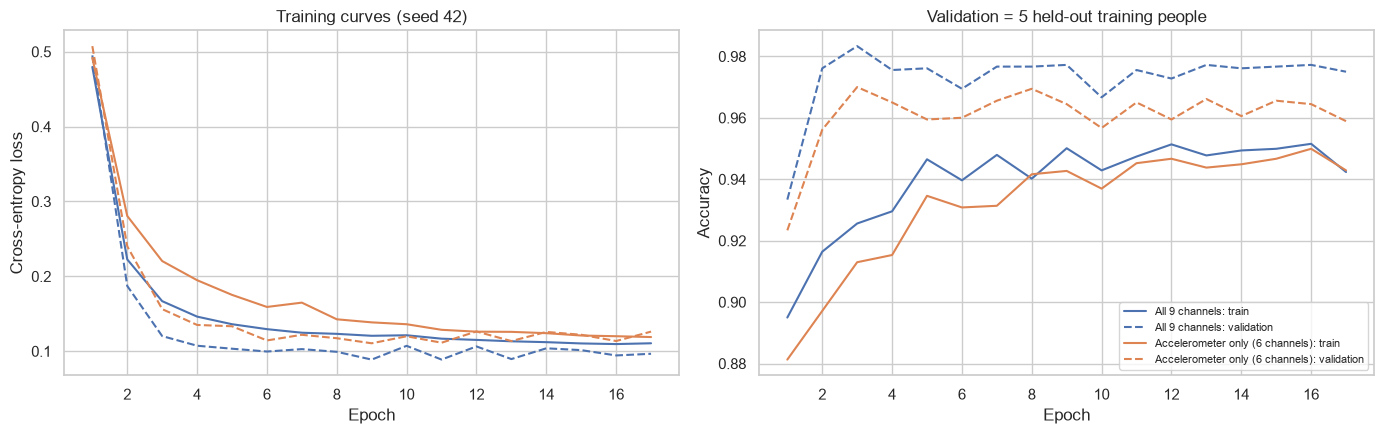

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (config, seed), history in histories.items():
    if seed != RANDOM_STATE:
        continue
    for ax, metric in zip(axes, ("loss", "accuracy")):
        line, = ax.plot(history["epoch"], history[f"train_{metric}"],
                        label=f"{config}: train")
        ax.plot(history["epoch"], history[f"val_{metric}"], "--",
                color=line.get_color(), label=f"{config}: validation")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
axes[0].set_title("Training curves (seed 42)")
n_val_people = len(set(subject_train[val_idx].tolist()))
axes[1].set_title(f"Validation = {n_val_people} held-out training people")
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
save_figure(fig, "C_cnn_training_curves")
plt.show()

**Observations.** The network learns quickly: validation accuracy passes 90% within a few epochs. Early stopping ends most runs after 16 or 17 epochs (one accelerometer-only run went to 43). The CNN is small (**12,166 parameters**), but unlike the SVM it works directly on the raw signals, so the phone does not need to compute the 561 features first.

Validation accuracy (97.1 to 97.6%) is much higher than test accuracy (about 90%, Section 5). The validation people chosen by the split (subjects 1, 3, 15, 25 and 27) all score 96 to 99% in the leave-one-person-out results of `C_clustering_generalization.ipynb`, so they happen to be easy people. This is the person-to-person variation again: with only 21 training people, any small validation set can be unrepresentative.

## 5. CNN vs. engineered features

The comparison uses the saved test results of the linear SVM on
engineered features from Person A (all 561) and Person B (accelerometer
only, all 348), so every number comes from the same 9 test people.

,input,model,test_f1_macro,test_f1_std
0,All sensors,"Linear SVM, 561 engineered features",0.9629,0.0000
1,All sensors,"1D CNN, raw signals (9 channels)",0.9022,0.0037
2,Accelerometer only,"Linear SVM, 348 engineered features",0.9122,0.0000
3,Accelerometer only,"1D CNN, raw signals (6 channels)",0.9034,0.0105


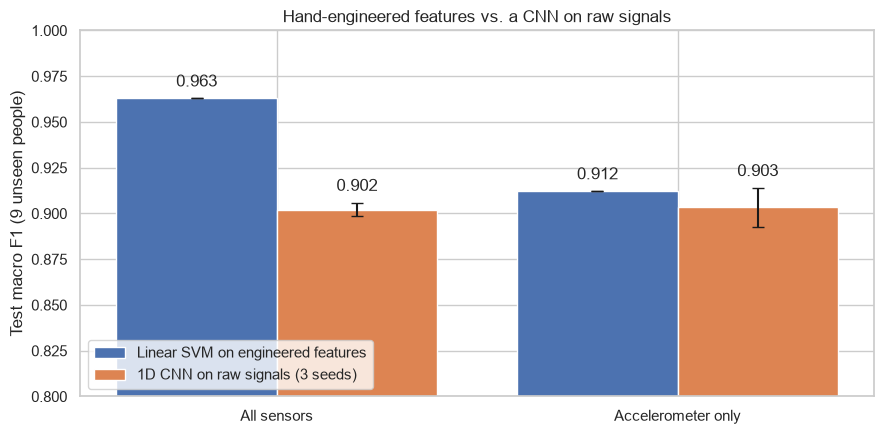

In [7]:
a_final = pd.read_csv(RESULTS_DIR / "A_final_comparison.csv", index_col=0)
b_final = pd.read_csv(RESULTS_DIR / "B_final_comparison.csv", index_col=0)

comparison = pd.DataFrame([
    {"input": "All sensors", "model": "Linear SVM, 561 engineered features",
     "test_f1_macro": a_final.loc["Linear SVM", "test_f1_macro"],
     "test_f1_std": 0.0},
    {"input": "All sensors", "model": "1D CNN, raw signals (9 channels)",
     "test_f1_macro": cnn_summary.loc["All 9 channels",
                                      ("test_f1_macro", "mean")],
     "test_f1_std": cnn_summary.loc["All 9 channels",
                                    ("test_f1_macro", "std")]},
    {"input": "Accelerometer only",
     "model": "Linear SVM, 348 engineered features",
     "test_f1_macro": b_final.loc["Accelerometer only, all 348",
                                  "test_f1_macro"],
     "test_f1_std": 0.0},
    {"input": "Accelerometer only",
     "model": "1D CNN, raw signals (6 channels)",
     "test_f1_macro": cnn_summary.loc["Accelerometer only (6 channels)",
                                      ("test_f1_macro", "mean")],
     "test_f1_std": cnn_summary.loc["Accelerometer only (6 channels)",
                                    ("test_f1_macro", "std")]},
])
save_results(comparison.set_index(["input", "model"]), "C_cnn_vs_features")
display(comparison)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(2)
for offset, kind in ((-0.2, "Linear SVM"), (0.2, "1D CNN")):
    part = comparison[comparison["model"].str.startswith(kind)]
    bars = ax.bar(x + offset, part["test_f1_macro"], width=0.4,
                  yerr=part["test_f1_std"], capsize=4,
                  label="Linear SVM on engineered features"
                  if kind == "Linear SVM" else "1D CNN on raw signals (3 seeds)")
    ax.bar_label(bars, fmt="%.3f", padding=6)
ax.set_xticks(x, ["All sensors", "Accelerometer only"])
ax.set_ylim(0.8, 1.0)
ax.set_ylabel("Test macro F1 (9 unseen people)")
ax.set_title("Hand-engineered features vs. a CNN on raw signals")
ax.legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "C_cnn_vs_features")
plt.show()

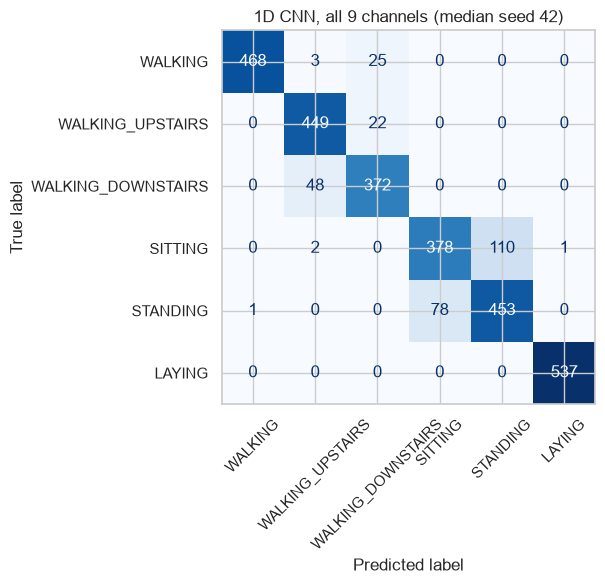

                    precision    recall  f1-score   support

           WALKING      0.998     0.944     0.970       496
  WALKING_UPSTAIRS      0.894     0.953     0.923       471
WALKING_DOWNSTAIRS      0.888     0.886     0.887       420
           SITTING      0.829     0.770     0.798       491
          STANDING      0.805     0.852     0.827       532
            LAYING      0.998     1.000     0.999       537

          accuracy                          0.902      2947
         macro avg      0.902     0.901     0.901      2947
      weighted avg      0.903     0.902     0.902      2947



In [8]:
best_seed = cnn_runs[cnn_runs["config"] == "All 9 channels"].sort_values(
    "test_f1_macro").iloc[1]["seed"]  # median of the 3 seeds
pred = test_preds[("All 9 channels", best_seed)]

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_raw_test, pred, display_labels=labels, xticks_rotation=45,
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"1D CNN, all 9 channels (median seed {best_seed})")
fig.tight_layout()
save_figure(fig, "C_cnn_confusion_matrix")
plt.show()
print(classification_report(y_raw_test, pred, target_names=labels,
                            digits=3))

**Observations.**

| Input | Linear SVM on engineered features | 1D CNN on raw signals (3 seeds) |
|---|---|---|
| All sensors | **0.963** | 0.902 ± 0.004 |
| Accelerometer only | **0.912** | 0.903 ± 0.011 |

1. **The engineered features win.** With all sensors, the CNN is about 6 points of macro F1 behind the linear SVM on the 561 features. The features contain expert knowledge that a small CNN does not learn from 21 people: they separate gravity from body motion, and they include frequency-domain (FFT) statistics and angles between the phone and gravity. These are exactly the gravity and orientation features that Person B found most important.
2. **For the CNN, the gyroscope adds nothing.** The 6-channel accelerometer CNN scores the same as the 9-channel CNN (0.903 vs. 0.902), and only 1 point below the SVM on all 348 accelerometer features. This supports Person B's conclusion that the accelerometer carries most of the information.
3. **Same weak spot.** The CNN's confusion matrix shows the familiar pattern: lying is near-perfect (F1 0.999) and walking is strong (0.970). The errors are mostly **sitting vs. standing** (F1 0.798 and 0.827), plus walking downstairs (0.887). Learning features from raw signals does not remove the posture ambiguity.
4. **What could close the gap** (not tested, given the time available): a deeper network or an LSTM layer, data augmentation (rotation and scaling of the signals), feeding the CNN the gravity component separately, tuning the learning rate and filter counts, or combining the CNN with the engineered features.

**Answer to the question:** on this dataset, hand-engineered features are still worth having. They give better accuracy than a small CNN trained on 21 people, and a linear model on top of them trains in about 3 seconds instead of about 45.